# 05. Data Augmentation Experiments — ResNet18

## Goal

Evaluate whether controlled, **lab-only augmentation** improves ResNet18 validation performance relative to the previously trained baseline.

**Protocol**

- Train: `data/splits/lab_train.csv` (PlantVillage only).
- Select checkpoint: `data/splits/lab_val.csv`, by macro-F1.
- Preserve the baseline model, initial ImageNet weights, seed, optimizer, training budget, and evaluation preprocessing.
- Modify **training transformations only**, one augmentation family at a time.
- Do **not** use `lab_test.csv` or `field_test.csv` for tuning, selection, or early stopping.
- The previously inspected 47-image PlantDoc test set must not be treated as an untouched confirmatory set for subsequent iterations. A separate field test is needed for final claims.

The baseline did not use stochastic training augmentation. This notebook runs **one augmentation preset per execution**, saving outputs separately.

## 1. Connect to Google Colab GPU and sync the repository

Only training requires Colab GPU. Run data preparation, CSV summaries, and reports locally on your Mac.

In [1]:
%pip install -q datasets pandas scikit-learn matplotlib pillow

import sys
import subprocess
from pathlib import Path
import torch

assert torch.cuda.is_available(), "Select a Colab GPU runtime before training."
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
PROJECT_ROOT = Path("/content/plant-disease-diagnosis")
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
GIT_SHA = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True
).strip()
print("Repository commit:", GIT_SHA)


Python: 3.12.13
PyTorch: 2.10.0+cu128
GPU: Tesla T4
Repository commit: a1fb3f7c4bffe3c50445370065e1bc4e2c7458e0


## 2. Configure one experiment

Choose either `photometric` (lighting and blur) or `geometric` (crop, orientation, scale). Start with `photometric`. To run the second preset, change the value and **Restart and Run All** so all model and random states are reset.

Results are stored in distinct Google Drive folders and will not overwrite the baseline.

In [2]:
from google.colab import drive
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from src.dataset import PlantDiseaseDataset

drive.mount("/content/drive")

# Change to "geometric" for the second experiment.
EXPERIMENT = "geometric"
assert EXPERIMENT in {"photometric", "geometric"}

SEED = 42
BATCH_SIZE = 32
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 5
NUM_WORKERS = 0
DEVICE = torch.device("cuda")

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
assert SPLITS_DIR.exists(), "Push data/splits/ to GitHub before using Colab."
label_map = json.loads((SPLITS_DIR / "label_map.json").read_text(encoding="utf-8"))
CLASS_NAMES = [name for name, i in sorted(label_map.items(), key=lambda x: x[1])]
assert len(CLASS_NAMES) == 5

RESULTS_DIR = Path("/content/drive/MyDrive/plant-disease-diagnosis") / f"resnet18_aug_{EXPERIMENT}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT = RESULTS_DIR / "resnet18_best.pt"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Experiment:", EXPERIMENT)
print("Labels:", CLASS_NAMES)
print("Results:", RESULTS_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment: geometric
Labels: ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot', 'Septoria Leaf Spot']
Results: /content/drive/MyDrive/plant-disease-diagnosis/resnet18_aug_geometric


## 3. Define training augmentation and fixed evaluation preprocessing

All validation images use the **unchanged** pretrained ResNet18 inference preprocessing. Only images from `lab_train.csv` are randomly transformed.

- **Photometric:** mild brightness, contrast, saturation and hue changes; occasional mild Gaussian blur.
- **Geometric:** moderate random crop/scale changes, horizontal flipping and rotation.

These transformations approximate some acquisition variation. They are not guaranteed to represent real field conditions, and overly aggressive transformations can remove disease evidence.

In [3]:
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
val_transform = WEIGHTS.transforms()
mean, std = WEIGHTS.transforms().mean, WEIGHTS.transforms().std

if EXPERIMENT == "photometric":
    train_transform = transforms.Compose([
        transforms.Resize(256, interpolation=InterpolationMode.BILINEAR),
        transforms.CenterCrop(224),
        transforms.ColorJitter(brightness=0.25, contrast=0.25,
                               saturation=0.20, hue=0.03),
        transforms.RandomApply([
            transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
        ], p=0.20),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
else:
    train_transform = transforms.Compose([
        transforms.Resize(256, interpolation=InterpolationMode.BILINEAR),
        transforms.RandomResizedCrop(224, scale=(0.80, 1.00),
                                     ratio=(0.90, 1.10),
                                     interpolation=InterpolationMode.BILINEAR),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=12, interpolation=InterpolationMode.BILINEAR),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

train_dataset = PlantDiseaseDataset(SPLITS_DIR / "lab_train.csv", transform=train_transform)
val_dataset = PlantDiseaseDataset(SPLITS_DIR / "lab_val.csv", transform=val_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)

images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 224, 224)
assert all(0 <= int(x) < 5 for x in labels)
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Batch shape:", tuple(images.shape))
print("Train augmentation:", train_transform)
print("Fixed validation preprocessing:", val_transform)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Train images: 5365
Validation images: 1341
Batch shape: (32, 3, 224, 224)
Train augmentation: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-12.0, 12.0], interpolation=bilinear, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Fixed validation preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 4. Inspect transformed images

Visually inspect a small training sample before running the full experiment. Confirm the augmented leaves still show recognizable disease symptoms and that important lesions are not routinely cropped out.

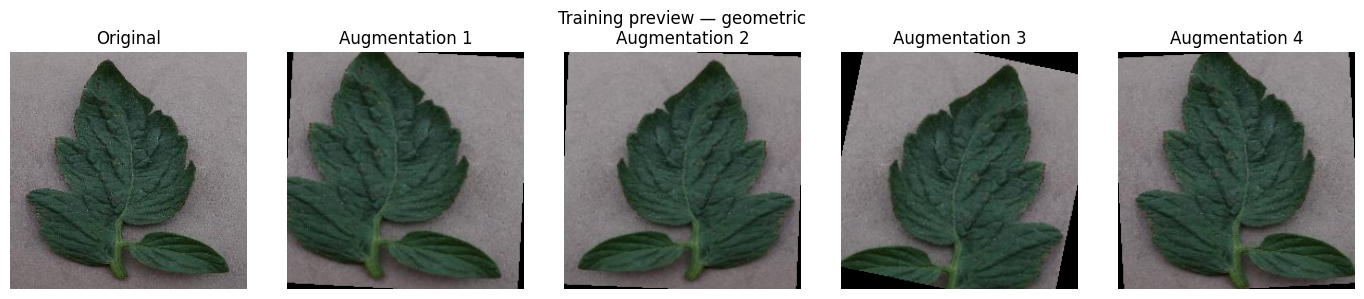

In [4]:
from torchvision.transforms.functional import to_pil_image

sample = train_dataset.source_datasets["plantvillage"][int(train_dataset.metadata.iloc[0]["row_id"])]["image"].convert("RGB")
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(sample)
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(1, 5):
    image = train_transform(sample)
    restored = image * torch.as_tensor(std).view(3, 1, 1) + torch.as_tensor(mean).view(3, 1, 1)
    axes[i].imshow(to_pil_image(restored.clamp(0, 1)))
    axes[i].set_title(f"Augmentation {i}")
    axes[i].axis("off")
plt.suptitle(f"Training preview — {EXPERIMENT}")
plt.tight_layout()
plt.show()


## 5. Initialize the same ResNet18 training protocol

Use ImageNet-pretrained ResNet18 with a fresh five-class head. Train the head for three epochs and then fine-tune the full network for five epochs using the exact learning rates and optimizer settings from the earlier CNN baseline. Select the checkpoint by **Lab Validation macro-F1**.

In [5]:
# Reset random states after augmentation preview for repeatable initialization.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = resnet18(weights=WEIGHTS)
model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()

for name, param in model.named_parameters():
    param.requires_grad = name.startswith("fc.")

history = []
best_f1 = -1.0


def run_epoch(loader, optimizer=None, freeze_backbone=False):
    is_training = optimizer is not None
    model.train(is_training)
    if is_training and freeze_backbone:
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()

    total_loss, all_true, all_pred = 0.0, [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if is_training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(labels)
        all_true.extend(labels.detach().cpu().tolist())
        all_pred.extend(logits.detach().argmax(dim=1).cpu().tolist())
    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(all_true, all_pred, labels=list(range(5)),
                             average="macro", zero_division=0),
    }


def train_phase(phase, n_epochs, optimizer, freeze_backbone=False):
    global best_f1
    for epoch in range(1, n_epochs + 1):
        train_metrics = run_epoch(train_loader, optimizer=optimizer, freeze_backbone=freeze_backbone)
        val_metrics = run_epoch(val_loader)
        record = {
            "experiment": EXPERIMENT,
            "phase": phase,
            "epoch_in_phase": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
        }
        history.append(record)
        pd.DataFrame(history).to_csv(RESULTS_DIR / "training_history.csv", index=False)
        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            torch.save({
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "architecture": "resnet18",
                "pretrained_weights": "IMAGENET1K_V1",
                "best_val_macro_f1": best_f1,
                "phase": phase,
                "epoch_in_phase": epoch,
                "seed": SEED,
                "augmentation": EXPERIMENT,
                "repository_commit": GIT_SHA,
            }, CHECKPOINT)
        print(f"{phase} | {epoch}/{n_epochs} | train F1={train_metrics['macro_f1']:.4f} "
              f"val F1={val_metrics['macro_f1']:.4f} val loss={val_metrics['loss']:.4f} "
              f"best={best_f1:.4f}")


## 6. Phase 1 — Train the classifier head

In [6]:
head_optimizer = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
train_phase("classifier_head", HEAD_EPOCHS, head_optimizer, freeze_backbone=True)


classifier_head | 1/3 | train F1=0.7165 val F1=0.8124 val loss=0.5171 best=0.8124
classifier_head | 2/3 | train F1=0.8561 val F1=0.8560 val loss=0.3867 best=0.8560
classifier_head | 3/3 | train F1=0.8857 val F1=0.8458 val loss=0.3749 best=0.8560


## 7. Phase 2 — Fine-tune the backbone

In [7]:
for parameter in model.parameters():
    parameter.requires_grad = True

finetune_optimizer = torch.optim.AdamW([
    {"params": [p for name, p in model.named_parameters() if not name.startswith("fc.")], "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 5e-4},
], weight_decay=1e-4)
train_phase("full_finetune", FINETUNE_EPOCHS, finetune_optimizer)


full_finetune | 1/5 | train F1=0.9298 val F1=0.9385 val loss=0.1705 best=0.9385
full_finetune | 2/5 | train F1=0.9832 val F1=0.9096 val loss=0.2868 best=0.9385
full_finetune | 3/5 | train F1=0.9883 val F1=0.9651 val loss=0.1071 best=0.9651
full_finetune | 4/5 | train F1=0.9881 val F1=0.9717 val loss=0.0949 best=0.9717
full_finetune | 5/5 | train F1=0.9922 val F1=0.9753 val loss=0.0977 best=0.9753


## 8. Training curves and validation comparison

Compare the new experiment's best **Lab Validation macro-F1** with the previous no-augmentation ResNet18 baseline. This is a development comparison, not evidence of field improvement.

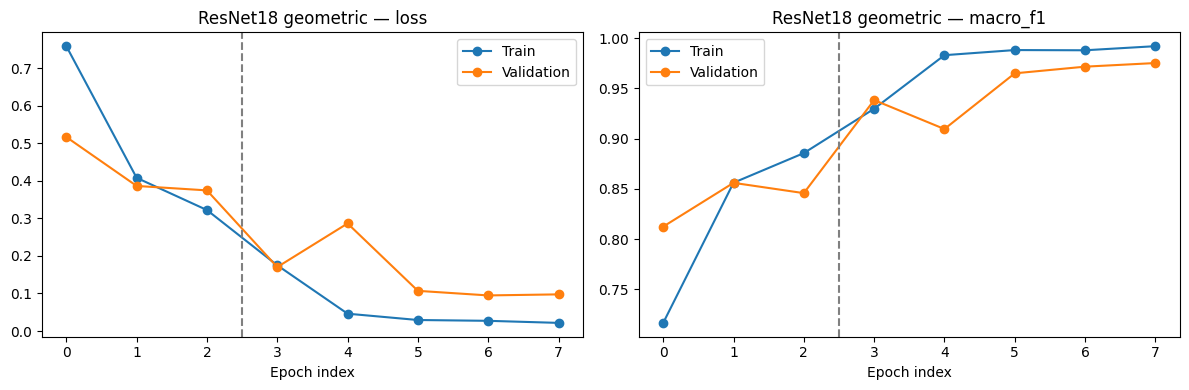

Baseline best Lab Validation macro-F1: 0.9879
geometric best Lab Validation macro-F1: 0.9753
Difference: -0.0125
Best checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/resnet18_aug_geometric/resnet18_best.pt


In [8]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in (("loss", axes[0]), ("macro_f1", axes[1])):
    ax.plot(history_df[f"train_{metric}"], label="Train", marker="o")
    ax.plot(history_df[f"val_{metric}"], label="Validation", marker="o")
    ax.axvline(HEAD_EPOCHS - 0.5, linestyle="--", color="gray")
    ax.set_title(f"ResNet18 {EXPERIMENT} — {metric}")
    ax.set_xlabel("Epoch index")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves.png", dpi=160)
plt.show()

baseline_history_path = Path("/content/drive/MyDrive/plant-disease-diagnosis/resnet18_baseline/training_history.csv")
if baseline_history_path.exists():
    baseline_f1 = pd.read_csv(baseline_history_path)["val_macro_f1"].max()
    print(f"Baseline best Lab Validation macro-F1: {baseline_f1:.4f}")
    print(f"{EXPERIMENT} best Lab Validation macro-F1: {best_f1:.4f}")
    print(f"Difference: {best_f1 - baseline_f1:+.4f}")
else:
    print("Baseline history not found on Drive; compare using the baseline training notebook.")

print("Best checkpoint:", CHECKPOINT)


## 9. Best-checkpoint validation report

Reload the best checkpoint and report class-level precision, recall, F1 and confusion matrix on **Lab Validation** only.

                    precision    recall  f1-score   support

           Healthy     0.9655    0.9960    0.9805       253
      Early Blight     0.9675    0.9313    0.9490       160
       Late Blight     1.0000    0.9575    0.9783       306
    Bacterial Spot     0.9912    0.9882    0.9897       340
Septoria Leaf Spot     0.9592    1.0000    0.9792       282

          accuracy                         0.9784      1341
         macro avg     0.9767    0.9746    0.9753      1341
      weighted avg     0.9788    0.9784    0.9783      1341



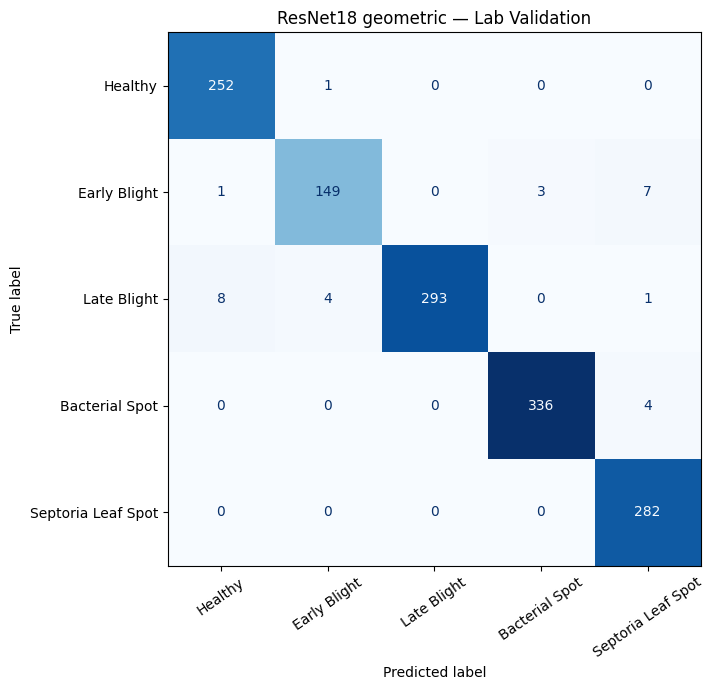

Saved experiment outputs to: /content/drive/MyDrive/plant-disease-diagnosis/resnet18_aug_geometric


In [9]:
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
assert checkpoint["class_names"] == CLASS_NAMES
assert checkpoint["augmentation"] == EXPERIMENT
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

true, predicted = [], []
with torch.inference_mode():
    for images, labels in val_loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        predicted.extend(logits.argmax(dim=1).cpu().tolist())
        true.extend(labels.tolist())

report = classification_report(true, predicted, labels=list(range(5)),
                               target_names=CLASS_NAMES, digits=4, zero_division=0)
print(report)
(RESULTS_DIR / "validation_classification_report.txt").write_text(report, encoding="utf-8")
cm = confusion_matrix(true, predicted, labels=list(range(5)))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
ax.set_title(f"ResNet18 {EXPERIMENT} — Lab Validation")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validation_confusion_matrix.png", dpi=160)
plt.show()
print("Saved experiment outputs to:", RESULTS_DIR)


## 10. Interpretation and next steps

After running each preset, record:

- Its best **Lab Validation macro-F1** relative to the no-augmentation baseline.
- Whether the transformed examples preserve recognizable disease symptoms.
- Which classes improve or degrade on validation.
- Whether training becomes less overfit or simply harder.

**Research limitation:** Lab Validation does not directly measure field generalization. The previously inspected 47-image Field Test must not be used repeatedly to optimize augmentations. Establish a separate target-domain development set from the **original PlantDoc training partition**, and reserve an independent field test for confirmation. After that protocol is fixed, repeat the same ablations for ViT-Small.

### Augmentation Results on Field Development Data

Both augmentation strategies improved cross-domain performance compared with the ResNet18 baseline.

Photometric augmentation increased field development macro-F1 from 0.2425 to 0.2694, while geometric augmentation achieved the highest macro-F1 of 0.2865.

Interestingly, both strategies reduced performance on laboratory validation data. This suggests a potential trade-off between in-domain performance and cross-domain generalization.

However, the improvements were observed on a relatively small development set of 96 images and require further validation.

The next stage investigates whether supervised fine-tuning on PlantDoc images can further improve cross-domain classification performance.